# Evaluation

Run this notebook from the repository root or `notebooks/` after installing
`requirements.txt`. It evaluates the committed predictions without a GPU or source
images and writes the two comparison CSVs to `results/` and plots to `results/figures/`.


In [1]:
import pandas as pd
from jiwer import cer, wer

from pathlib import Path

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "results/vlm_full_results.csv").is_file()),
    None,
)
if PROJECT_ROOT is not None:
    RESULTS_PATH = PROJECT_ROOT / "results/vlm_full_results.csv"
else:
    RESULTS_PATH = next(
        (p for p in [Path("/content/results/vlm_full_results.csv"), Path("/content/vlm_full_results.csv")]
         if p.is_file()),
        None,
    )
if RESULTS_PATH is None:
    raise FileNotFoundError("Run from the cloned project, or upload vlm_full_results.csv to Colab.")
RESULTS_DIR = RESULTS_PATH.parent
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RESULTS_PATH, keep_default_na=False, dtype={"page_id": str, "line_id": str})
if df.duplicated(["page_id", "line_id"]).any():
    raise ValueError("Duplicate page/line IDs in VLM results.")

assert len(df) == 164

thresholds = [70, 80, 85, 90, 95]

results = []

for threshold in thresholds:

    selected = df["ocr_confidence"] < threshold

    final_text = df["ocr_text"].copy()
    final_text.loc[selected] = df.loc[selected, "vlm_text"]

    results.append({
        "threshold": threshold,
        "vlm_calls": int(selected.sum()),
        "selection_rate": selected.mean() * 100,
        "cer": cer(
            df["ground_truth"].tolist(),
            final_text.tolist()
        ),
        "wer": wer(
            df["ground_truth"].tolist(),
            final_text.tolist()
        )
    })

comparison = pd.DataFrame(results)

print(comparison.to_string(index=False))
comparison.to_csv(RESULTS_DIR / "selective_comparison.csv", index=False)


 threshold  vlm_calls  selection_rate      cer      wer
        70          4        2.439024 0.012532 0.079840
        80         14        8.536585 0.010492 0.070526
        85         24       14.634146 0.009909 0.066534
        90         59       35.975610 0.007189 0.051231
        95        141       85.975610 0.003303 0.026613


In [2]:
from jiwer import cer
import pandas as pd

df["ocr_line_cer"] = df.apply(
    lambda r: cer(r["ground_truth"], r["ocr_text"]),
    axis=1
)

df["vlm_line_cer"] = df.apply(
    lambda r: cer(r["ground_truth"], r["vlm_text"]),
    axis=1
)

df["vlm_worsens"] = (
    df["vlm_line_cer"] > df["ocr_line_cer"]
)

rows = []

for threshold in [70, 80, 85, 90, 95]:

    selected = df["ocr_confidence"] < threshold

    rows.append({
        "threshold": threshold,
        "selected_lines": int(selected.sum()),
        "regressions_activated": int(
            (selected & df["vlm_worsens"]).sum()
        ),
        "regressions_avoided": int(
            (~selected & df["vlm_worsens"]).sum()
        )
    })

regression_df = pd.DataFrame(rows)

print(regression_df.to_string(index=False))
regression_df.to_csv(RESULTS_DIR / "regression_analysis.csv", index=False)


 threshold  selected_lines  regressions_activated  regressions_avoided
        70               4                      0                    8
        80              14                      0                    8
        85              24                      1                    7
        90              59                      3                    5
        95             141                      7                    1


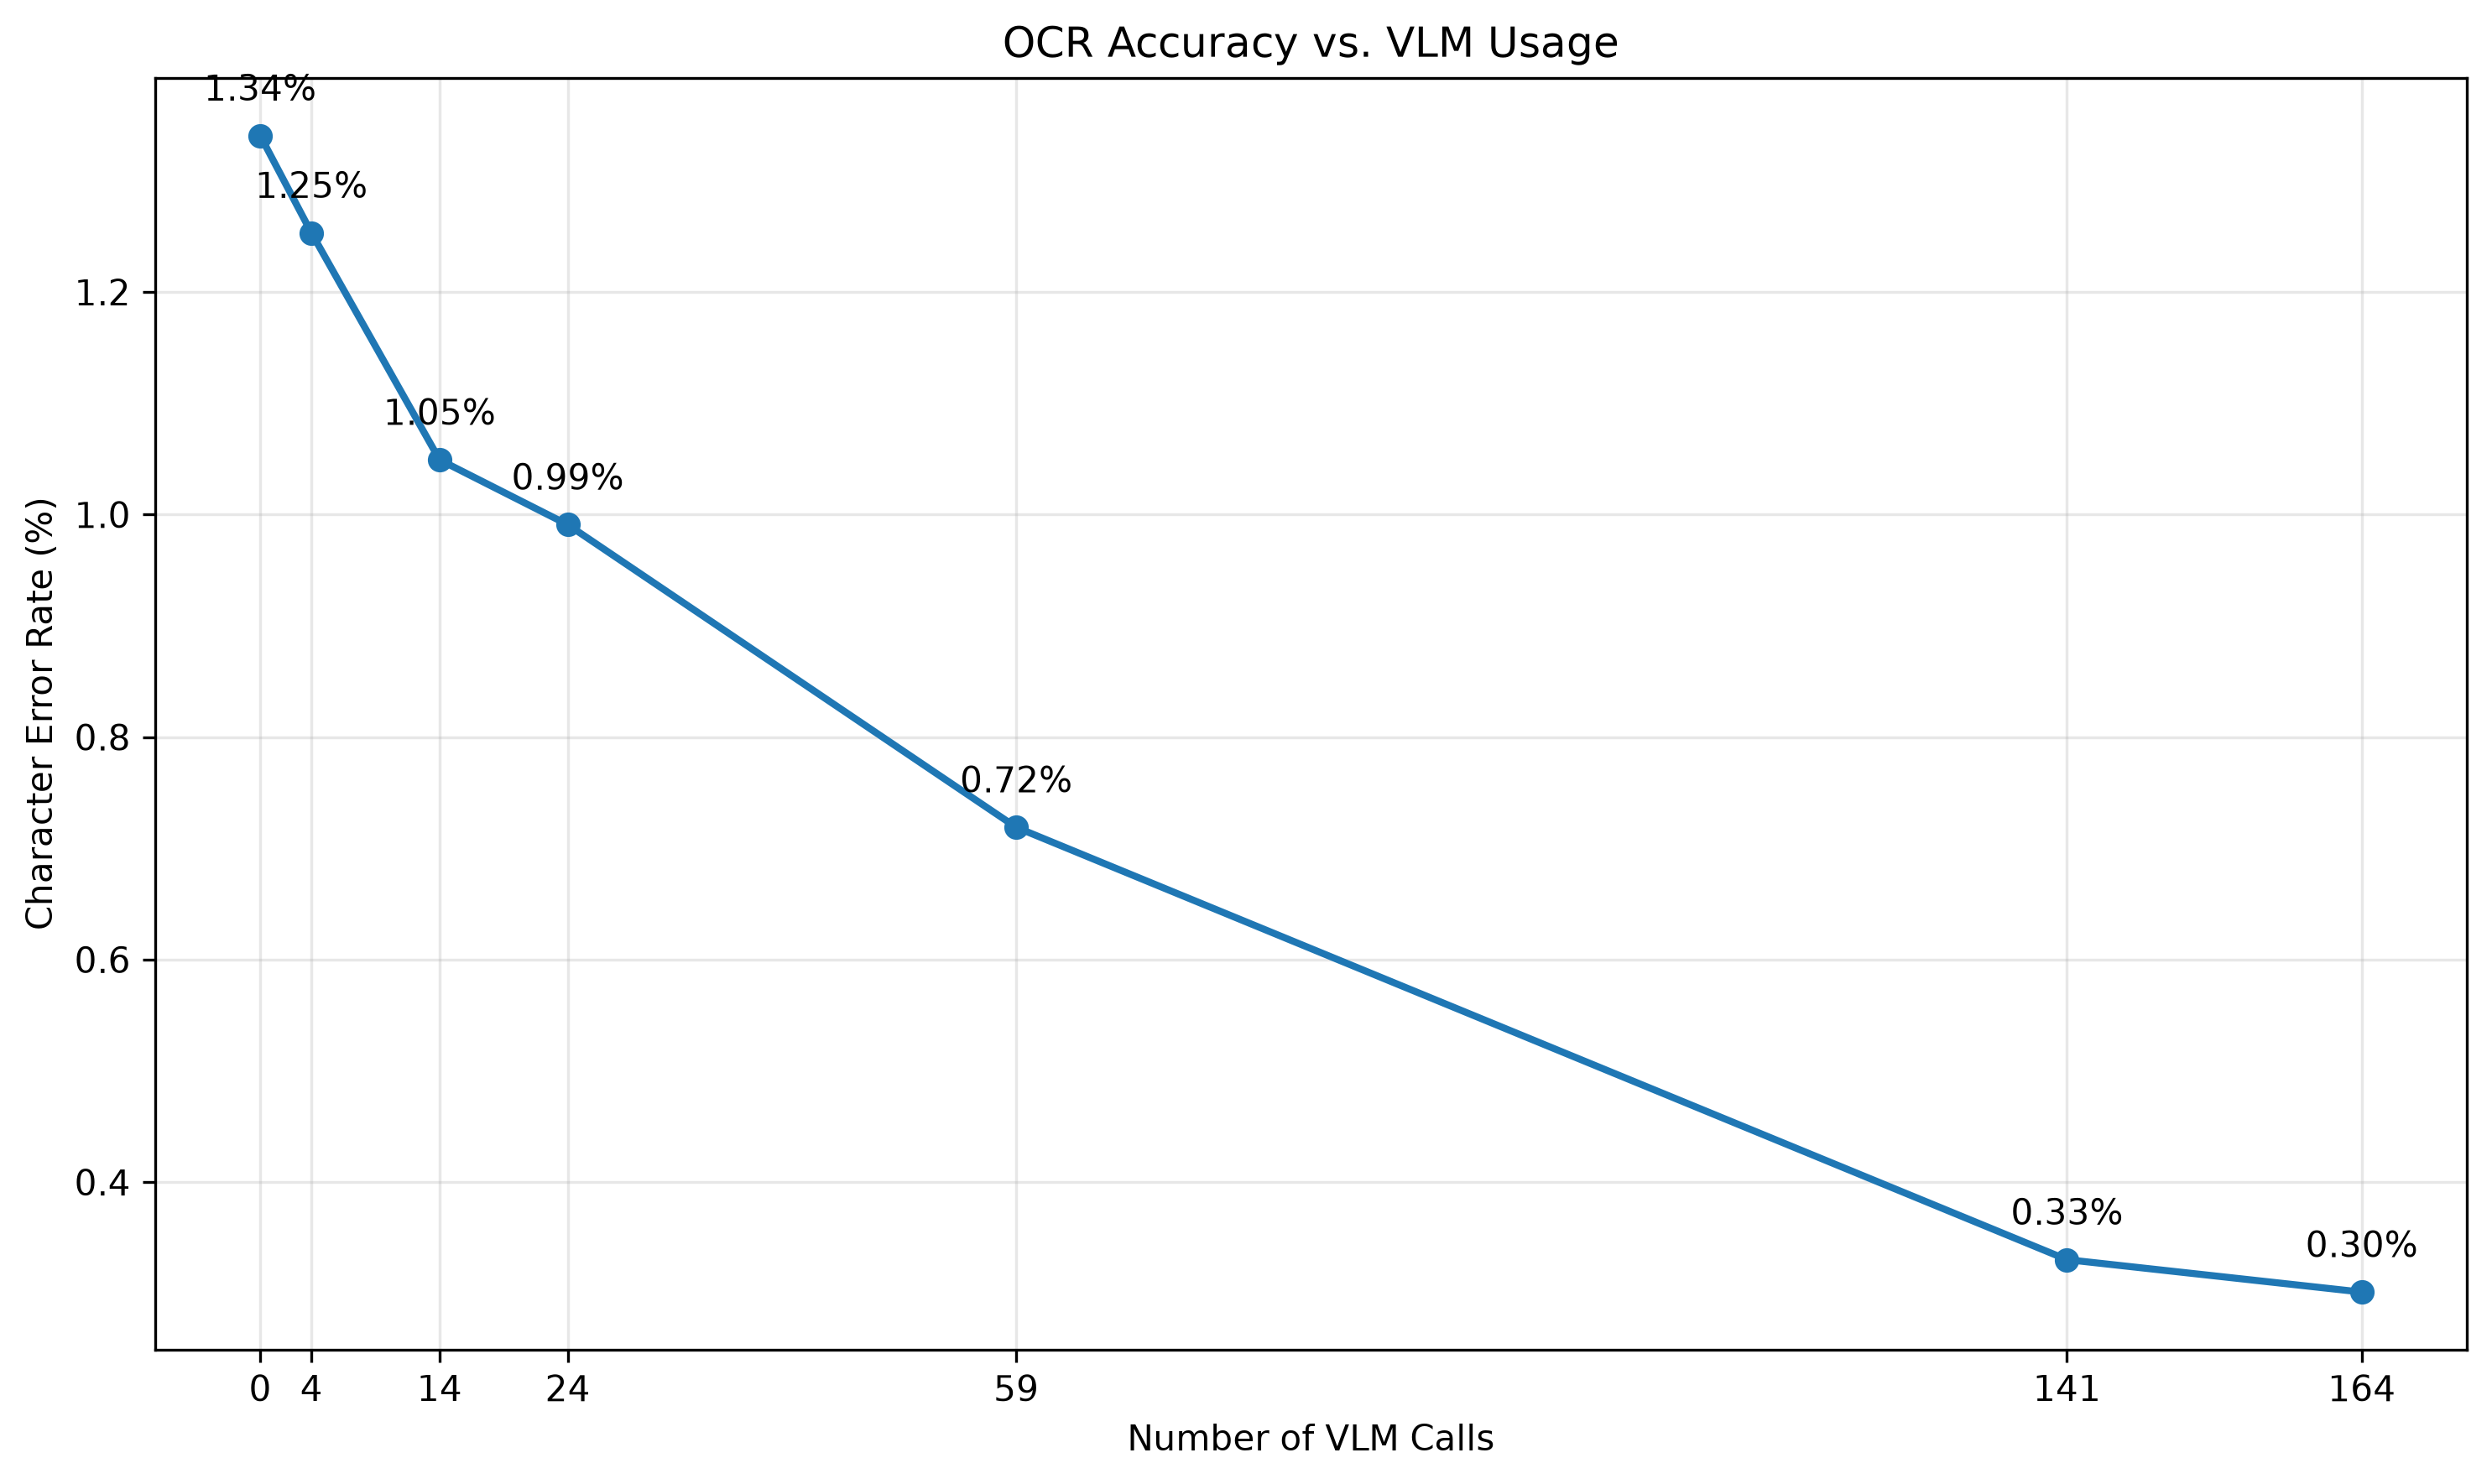

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from jiwer import cer

ocr_baseline_cer = cer(
    df["ground_truth"].tolist(),
    df["ocr_text"].tolist()
)

full_vlm_cer = cer(
    df["ground_truth"].tolist(),
    df["vlm_text"].tolist()
)

total_lines = len(df)

plot_df = pd.concat([
    pd.DataFrame([{
        "vlm_calls": 0,
        "cer": ocr_baseline_cer,
        "method": "OCR only"
    }]),
    comparison[["vlm_calls", "cer"]].assign(
        method="Selective"
    ),
    pd.DataFrame([{
        "vlm_calls": total_lines,
        "cer": full_vlm_cer,
        "method": "Full VLM"
    }])
], ignore_index=True)

plot_df = plot_df.sort_values("vlm_calls")

plt.figure(figsize=(10, 6))

plt.plot(
    plot_df["vlm_calls"],
    plot_df["cer"] * 100,
    marker="o",
    linewidth=2
)

for _, row in plot_df.iterrows():
    plt.annotate(
        f'{row["cer"] * 100:.2f}%',
        (row["vlm_calls"], row["cer"] * 100),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.xlabel("Number of VLM Calls")
plt.ylabel("Character Error Rate (%)")
plt.title("OCR Accuracy vs. VLM Usage")

plt.xticks(plot_df["vlm_calls"])
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cer_vs_vlm_calls.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

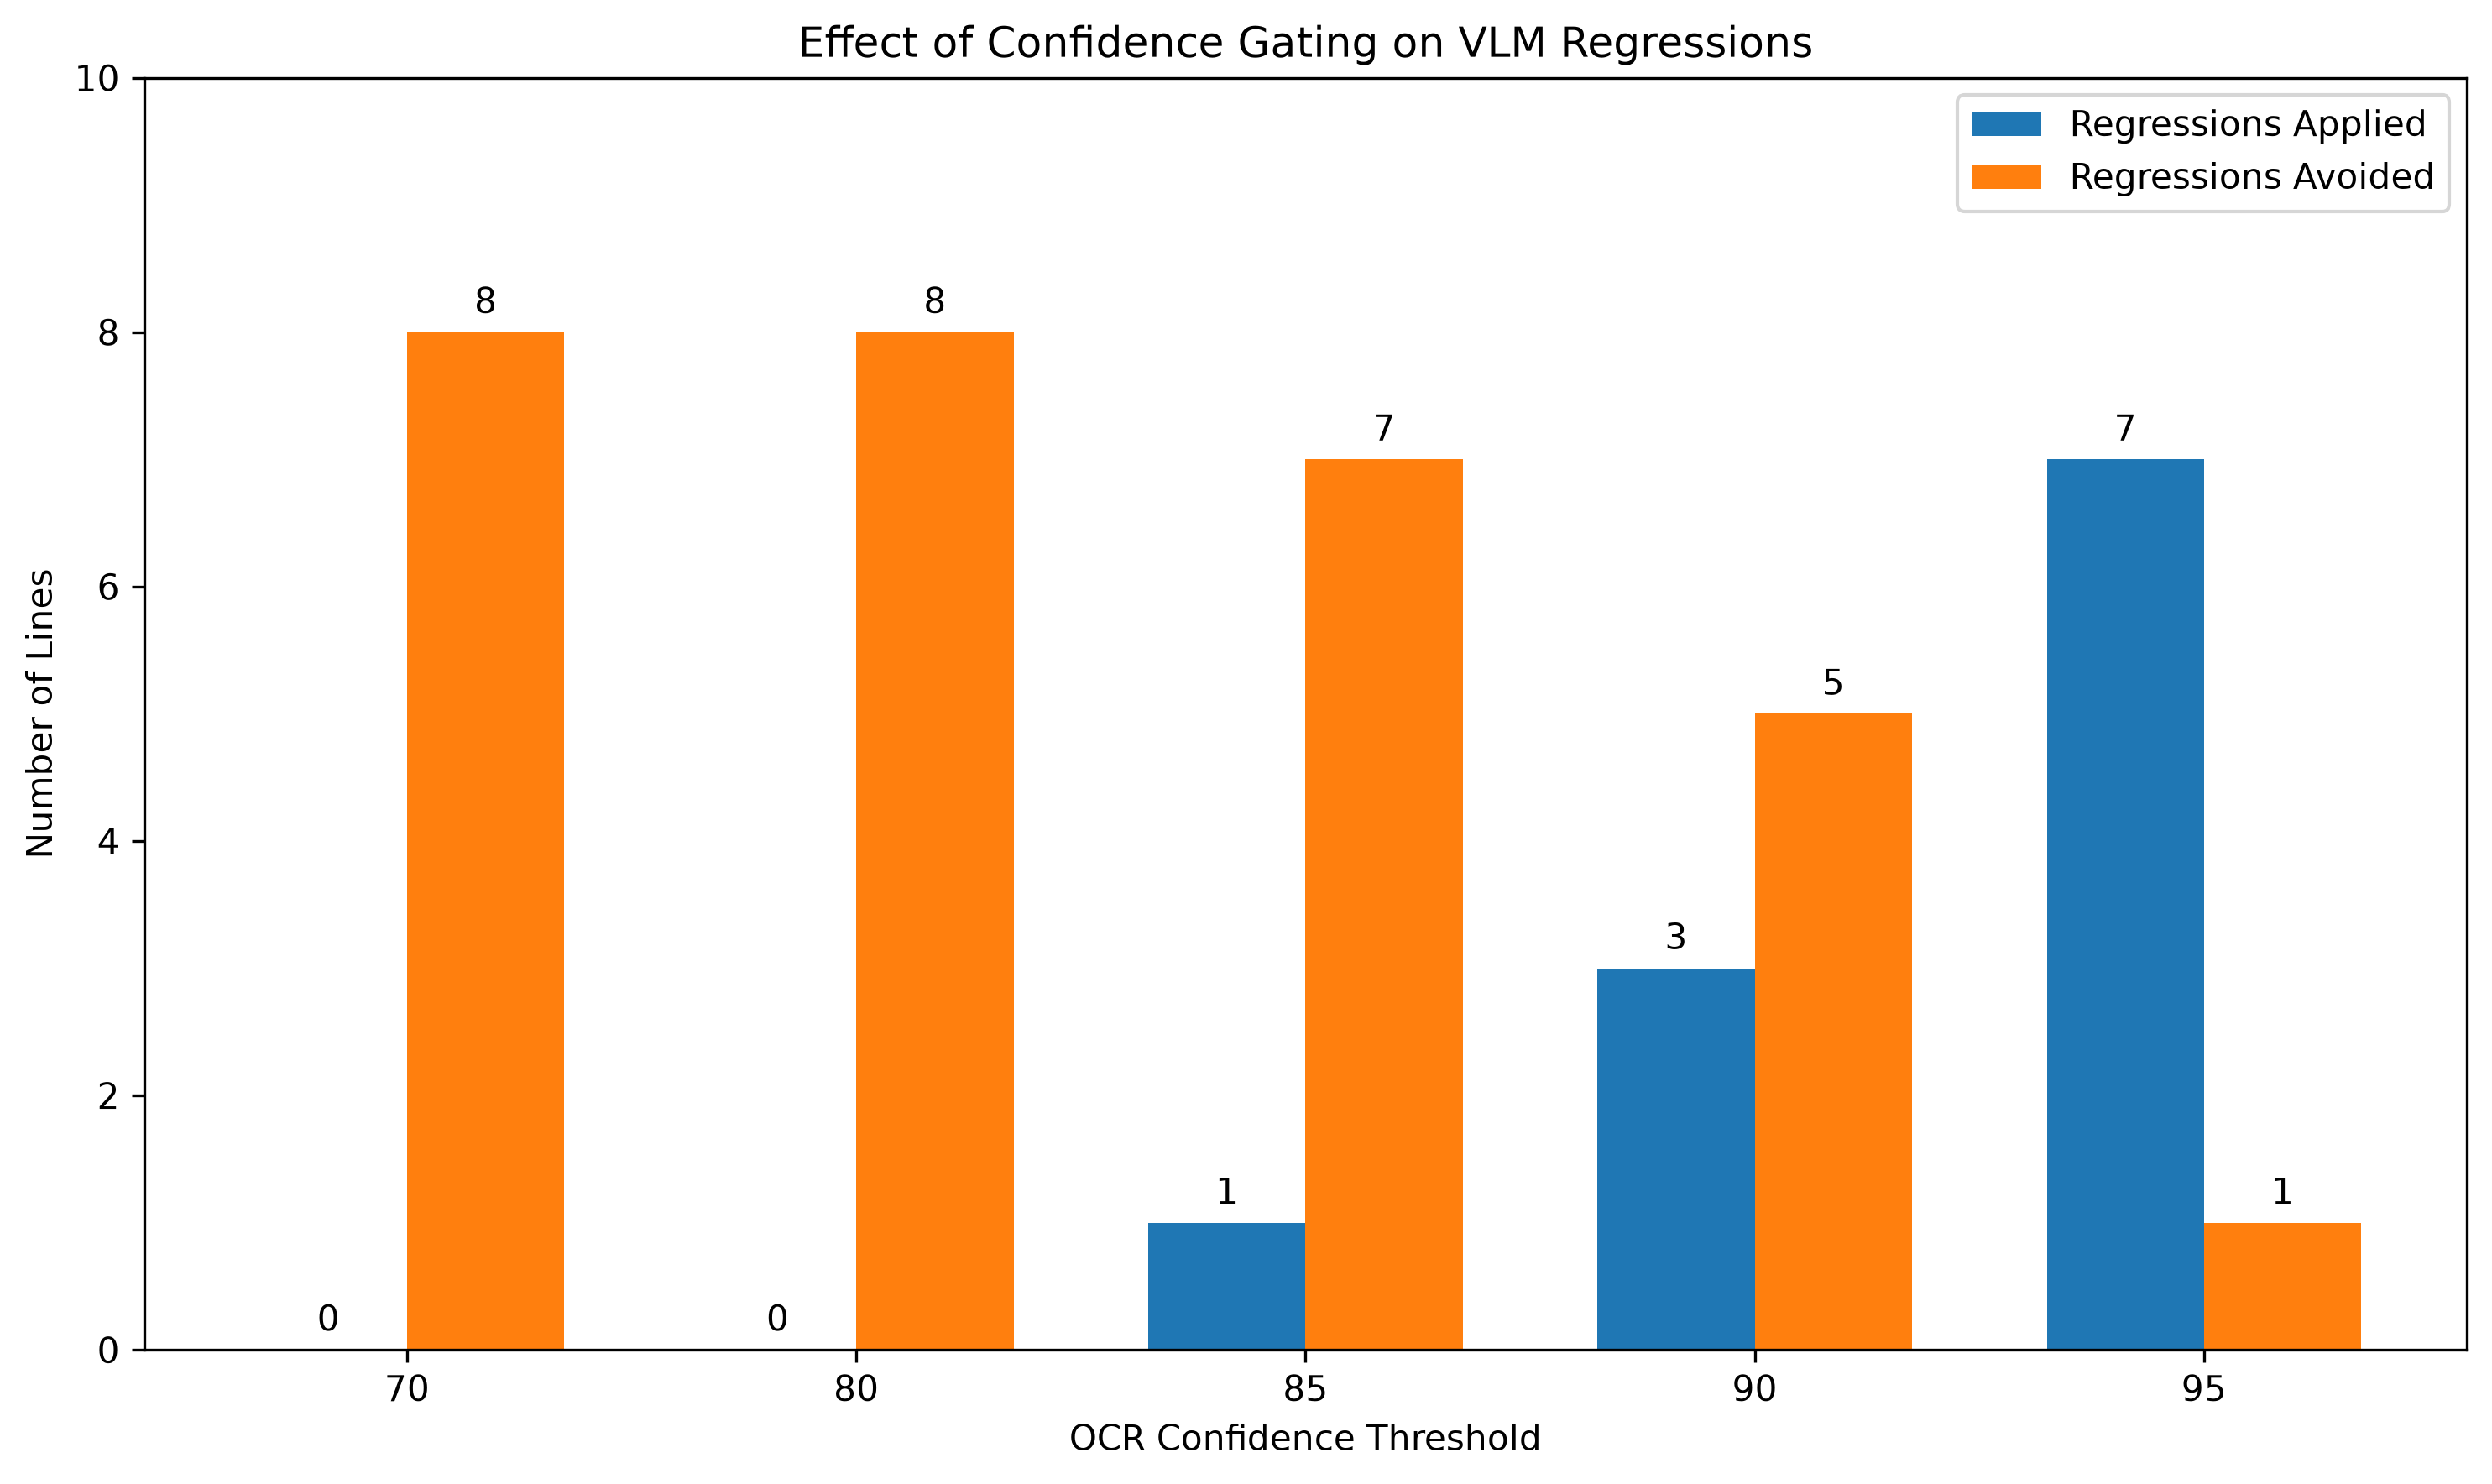

In [4]:
import numpy as np
import matplotlib.pyplot as plt

labels = regression_df["threshold"].astype(str)

activated = regression_df["regressions_activated"]
avoided = regression_df["regressions_avoided"]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    activated,
    width,
    label="Regressions Applied"
)

bars2 = ax.bar(
    x + width / 2,
    avoided,
    width,
    label="Regressions Avoided"
)

ax.set_xlabel("OCR Confidence Threshold")
ax.set_ylabel("Number of Lines")
ax.set_title("Effect of Confidence Gating on VLM Regressions")

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.legend()
ax.bar_label(bars1, padding=3)
ax.bar_label(bars2, padding=3)

ax.set_ylim(0, 10)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "vlm_regression_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Figure 1: OCR Accuracy vs. VLM Usage**

Increasing the number of lines selected for VLM correction generally reduces Character Error Rate. A confidence threshold of 90 achieves a CER of approximately 0.72% using 59 VLM calls, compared with 0.30% when all 164 lines are processed.

This demonstrates a trade-off between recognition accuracy and computational effort.

**Figure 2: Effect of Confidence Gating on VLM Regressions**

More conservative confidence thresholds avoid a greater number of harmful VLM corrections. At threshold 80, none of the eight observed regressions are applied, but many beneficial corrections are also excluded.

These results indicate that selective correction can reduce unnecessary modifications, although the confidence threshold must balance correction opportunities against regression risks.

Both analyses are exploratory and based on four pages from a single historical document.